In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss, brier_score_loss

os.makedirs("../figures", exist_ok=True)
oof = pd.read_csv("../data/oof_predictions.csv", index_col=0)
s, y, amt = oof["avg"].values, oof["y"].values, oof["amount"].values
print(len(oof), y.sum())          # expect 226980 378
assert (len(oof), int(y.sum())) == (226980, 378)

226980 378


## 1. Reliability table: does a score of X mean roughly X% fraud?

In [2]:
bins = [0, 0.001, 0.01, 0.05, 0.2, 0.5, 0.8, 1.0001]
tab = pd.DataFrame({"score": s, "y": y})
tab["bin"] = pd.cut(tab["score"], bins, right=False)
print(tab.groupby("bin", observed=True).agg(
    n=("y", "size"), frauds=("y", "sum"),
    mean_score=("score", "mean"), observed_rate=("y", "mean")).round(4))

                    n  frauds  mean_score  observed_rate
bin                                                     
[0.0, 0.001)   224004      38      0.0000         0.0002
[0.001, 0.01)    2392      18      0.0026         0.0075
[0.01, 0.05)      199       7      0.0202         0.0352
[0.05, 0.2)        49       9      0.1072         0.1837
[0.2, 0.5)         27      14      0.3764         0.5185
[0.5, 0.8)         49      39      0.6664         0.7959
[0.8, 1.0)        260     253      0.9779         0.9731


## 2. Compare calibrators on held-out folds

In [3]:
eps = 1e-6
def logit(p):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p)).reshape(-1, 1)

def platt(s_tr, y_tr, s_te):
    m = LogisticRegression(C=1e6, max_iter=1000).fit(logit(s_tr), y_tr)
    return m.predict_proba(logit(s_te))[:, 1]

def isotonic(s_tr, y_tr, s_te):
    m = IsotonicRegression(y_min=1e-5, y_max=1 - 1e-5, out_of_bounds="clip").fit(s_tr, y_tr)
    return m.predict(s_te)

cal = {"raw": s.copy(), "platt": np.zeros(len(s)), "isotonic": np.zeros(len(s))}
for tr, te in StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(s, y):
    cal["platt"][te] = platt(s[tr], y[tr], s[te])
    cal["isotonic"][te] = isotonic(s[tr], y[tr], s[te])

for name, p in cal.items():
    p = np.clip(p, eps, 1 - eps)
    print(f"{name:9s} log loss={log_loss(y, p):.5f}  brier={brier_score_loss(y, p):.6f}")
# Lower is better. Platt keeps the ranking identical, so PR-AUC is unchanged.

raw       log loss=0.00274  brier=0.000411
platt     log loss=0.00250  brier=0.000412
isotonic  log loss=0.00260  brier=0.000411


## 3. Cost-based rules

Flagging costs `R` (one analyst review). Not flagging costs `p * amount` in expectation, plus an optional
fixed loss per missed fraud (`extra_per_miss`, e.g. a chargeback fee). Two rules are compared:
a single global threshold (tuned on this same data, so slightly optimistic) and an amount-aware rule
that flags when `p * (amount + extra) > R` and has no tuned parameter.

In [4]:
CALIBRATOR = "platt"     # change to "raw" or "isotonic" based on the log-loss table above
p_cal = np.clip(cal[CALIBRATOR], eps, 1 - eps)

def cost(flag, R, fixed):
    missed = (~flag) & (y == 1)
    return (amt[missed] + fixed).sum() + R * flag.sum()

def summarize(flag, R, fixed, base):
    c = cost(flag, R, fixed)
    tp = int((flag & (y == 1)).sum())
    return dict(cost=round(c), saved_pct=round(100 * (base - c) / base, 1),
                flagged=int(flag.sum()), precision=round(tp / max(flag.sum(), 1), 3),
                recall=round(tp / y.sum(), 3))

thresholds = np.logspace(-4, -0.01, 300)
rows = []
for fixed in [0, 25]:
    base = cost(np.zeros(len(y), bool), 0, fixed)
    print(f"cost of flagging nothing (extra_per_miss={fixed}): {round(base)}")
    for R in [1, 5, 25]:
        costs = [cost(p_cal >= t, R, fixed) for t in thresholds]
        t_best = thresholds[int(np.argmin(costs))]
        rows.append({"extra_per_miss": fixed, "R": R, "rule": f"global t={t_best:.4f}",
                     **summarize(p_cal >= t_best, R, fixed, base)})
        rows.append({"extra_per_miss": fixed, "R": R, "rule": "amount-aware",
                     **summarize(p_cal * (amt + fixed) > R, R, fixed, base)})
results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv("../figures/cost_table.csv", index=False)

cost of flagging nothing (extra_per_miss=0): 45618
cost of flagging nothing (extra_per_miss=25): 55068
 extra_per_miss  R            rule  cost  saved_pct  flagged  precision  recall
              0  1 global t=0.0051  9427       79.3     2395      0.142   0.897
              0  1    amount-aware  7744       83.0     1589      0.128   0.540
              0  5 global t=0.0164 13569       70.3      765      0.430   0.870
              0  5    amount-aware 11559       74.7      438      0.393   0.455
              0 25 global t=0.4009 20239       55.6      324      0.932   0.799
              0 25    amount-aware 16820       63.1      165      0.818   0.357
             25  1 global t=0.0051 10402       81.1     2395      0.142   0.897
             25  1    amount-aware  9134       83.4     1916      0.173   0.876
             25  5 global t=0.0164 14794       73.1      765      0.430   0.870
             25  5    amount-aware 13109       76.2      625      0.506   0.836
             25 2

## 4. Figure for the README

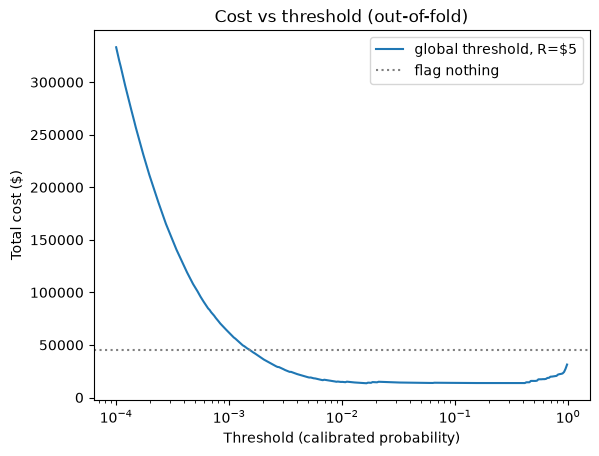

In [6]:
base0 = cost(np.zeros(len(y), bool), 0, 0)
plt.semilogx(thresholds, [cost(p_cal >= t, 5, 0) for t in thresholds], label="global threshold, R=$5")
plt.axhline(base0, ls=":", color="gray", label="flag nothing")
plt.legend(); plt.xlabel("Threshold (calibrated probability)"); plt.ylabel("Total cost ($)")
plt.title("Cost vs threshold (out-of-fold)")
plt.savefig("../figures/cost_vs_threshold.png", dpi=150); plt.show()

In [7]:
def per_txn_cost(flag, R, fixed):
    # flagged -> one review; unflagged fraud -> amount + fixed loss; unflagged legit -> 0
    return np.where(flag, R, np.where(y == 1, amt + fixed, 0.0))

best_t = {1: 0.0051, 5: 0.0164, 25: 0.4009}     # global thresholds from your cost table
rng = np.random.default_rng(0)
for fixed in [0, 25]:
    for R, t in best_t.items():
        diff = per_txn_cost(p_cal >= t, R, fixed) - per_txn_cost(p_cal * (amt + fixed) > R, R, fixed)
        boot = [diff[rng.integers(0, len(diff), len(diff))].sum() for _ in range(500)]
        lo, hi = np.percentile(boot, [2.5, 97.5])
        print(f"extra={fixed:>2} R={R:>2}: amount-aware saves ${diff.sum():,.0f}  (95% CI ${lo:,.0f} to ${hi:,.0f})")

extra= 0 R= 1: amount-aware saves $1,684  (95% CI $596 to $3,214)
extra= 0 R= 5: amount-aware saves $2,015  (95% CI $1,189 to $3,324)
extra= 0 R=25: amount-aware saves $3,418  (95% CI $2,778 to $4,058)
extra=25 R= 1: amount-aware saves $1,270  (95% CI $91 to $2,940)
extra=25 R= 5: amount-aware saves $1,690  (95% CI $190 to $4,035)
extra=25 R=25: amount-aware saves $-453  (95% CI $-771 to $-142)
